<a href="https://colab.research.google.com/github/abenezer1244-afk/financial-analysis-projections/blob/main/Finance_Portfolio_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Historical Financial Analysis: AAPL


,Revenue,Net Income,Operating Income,Operating Cash Flow,Capital Expenditure,Free Cash Flow,Net Profit Margin,Operating Margin
Fiscal Year,,,,,,,,
2022,"$394,328,000,000.00","$99,803,000,000.00","$119,437,000,000.00","$122,151,000,000.00","$10,708,000,000.00","$111,443,000,000.00",25.3%,30.3%
2023,"$383,285,000,000.00","$96,995,000,000.00","$114,301,000,000.00","$110,543,000,000.00","$10,959,000,000.00","$99,584,000,000.00",25.3%,29.8%
2024,"$391,035,000,000.00","$93,736,000,000.00","$123,216,000,000.00","$118,254,000,000.00","$9,447,000,000.00","$108,807,000,000.00",24.0%,31.5%
2025,"$416,161,000,000.00","$112,010,000,000.00","$133,050,000,000.00","$111,482,000,000.00","$12,715,000,000.00","$98,767,000,000.00",26.9%,32.0%



Historical Financials in Billions


,Revenue ($ Billions),Net Income ($ Billions),Operating Income ($ Billions),Operating Cash Flow ($ Billions),Capital Expenditure ($ Billions),Free Cash Flow ($ Billions),Net Profit Margin,Operating Margin
Fiscal Year,,,,,,,,
2022,$394.33,$99.80,$119.44,$122.15,$10.71,$111.44,25.3%,30.3%
2023,$383.29,$97.00,$114.30,$110.54,$10.96,$99.58,25.3%,29.8%
2024,$391.04,$93.74,$123.22,$118.25,$9.45,$108.81,24.0%,31.5%
2025,$416.16,$112.01,$133.05,$111.48,$12.71,$98.77,26.9%,32.0%



Historical Trend Summary
Historical period: 2022-2025
Revenue CAGR: 1.81%
Net income CAGR: 3.92%
Average net profit margin: 25.38%
Average free-cash-flow margin: 26.45%

Five-Year Financial Projections


,Scenario,Year,Projected Revenue ($ Billions),Projected Net Income ($ Billions),Projected Free Cash Flow ($ Billions),Growth Assumption,Net Margin Assumption
0,Bear Case,2026,$402.90,$90.15,$106.57,-3.2%,22.4%
1,Bear Case,2027,$390.05,$87.28,$103.17,-3.2%,22.4%
2,Bear Case,2028,$377.62,$84.49,$99.88,-3.2%,22.4%
3,Bear Case,2029,$365.58,$81.80,$96.70,-3.2%,22.4%
4,Bear Case,2030,$353.93,$79.19,$93.62,-3.2%,22.4%
5,Base Case,2026,$423.70,$107.52,$112.07,1.8%,25.4%
6,Base Case,2027,$431.38,$109.47,$114.10,1.8%,25.4%
7,Base Case,2028,$439.20,$111.45,$116.17,1.8%,25.4%
8,Base Case,2029,$447.16,$113.47,$118.28,1.8%,25.4%
9,Base Case,2030,$455.27,$115.53,$120.42,1.8%,25.4%


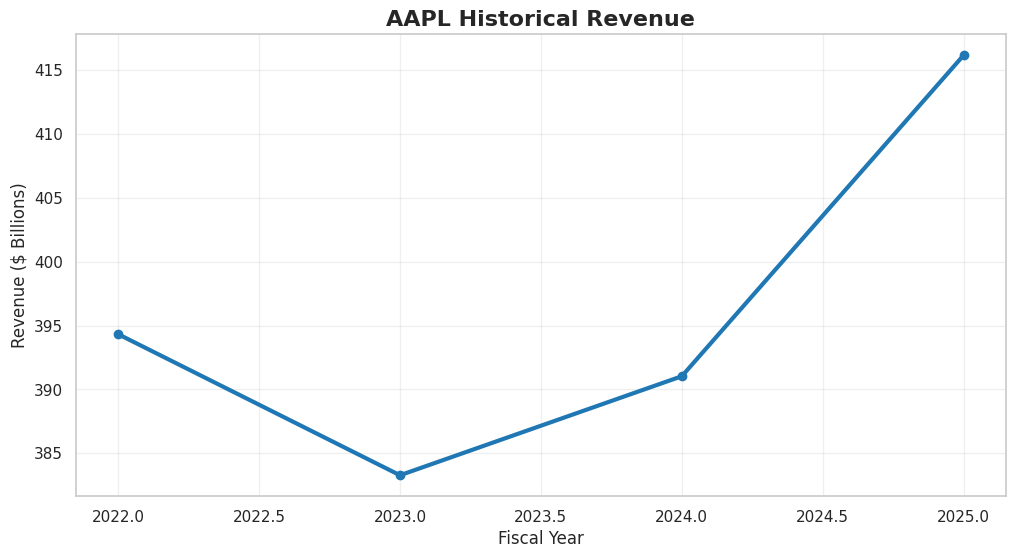

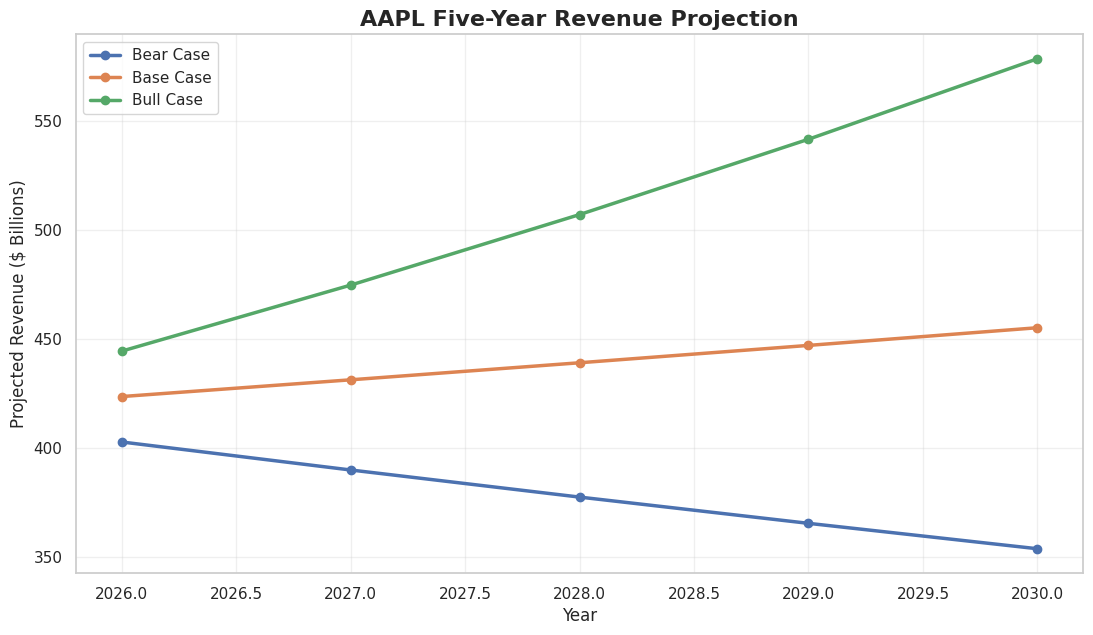

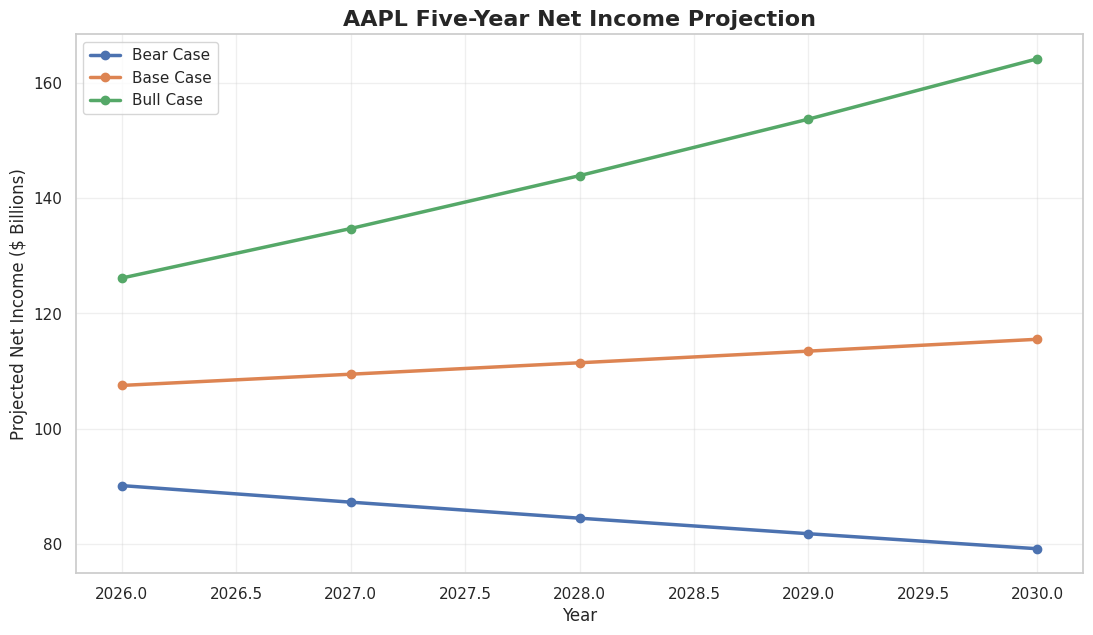


Project Interpretation
- The company currently reports a positive net profit margin.
- The company currently generates positive free cash flow.
- Historical revenue grew at approximately 1.81% per year.

Important: These are scenario-based estimates using historical growth and profitability. They are not guaranteed predictions or investment advice.

Files saved:
- AAPL_historical_financial_analysis.csv
- AAPL_five_year_projections.csv


In [3]:
!pip install -q yfinance seaborn

import warnings
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


# ============================================================
# ENTER ANY PUBLIC COMPANY TICKER HERE
# ============================================================

TICKER = "AAPL"       # Examples: MSFT, GOOGL, TSLA, AMZN, JPM
FORECAST_YEARS = 5


# ============================================================
# HELPER FUNCTIONS
# ============================================================

def clean_statement(statement):
    """Cleans and standardizes Yahoo Finance financial statements."""
    if statement is None or statement.empty:
        return pd.DataFrame()

    statement = statement.copy()

    try:
        statement.columns = pd.to_datetime(
            statement.columns,
            errors="coerce"
        )

        statement = statement.loc[
            :, ~statement.columns.isna()
        ]

        statement = statement.loc[
            :, ~statement.columns.duplicated()
        ]

        return statement.sort_index(axis=1)

    except Exception:
        return pd.DataFrame()


def find_metric(statement, possible_names):
    """Finds a financial metric despite different Yahoo Finance labels."""
    if statement is None or statement.empty:
        return pd.Series(dtype=float)

    normalized_rows = {}

    for row in statement.index:
        normalized_row = (
            str(row)
            .lower()
            .replace(" ", "")
            .replace("_", "")
            .replace("-", "")
            .replace("(", "")
            .replace(")", "")
        )
        normalized_rows[normalized_row] = row

    for name in possible_names:
        normalized_name = (
            name
            .lower()
            .replace(" ", "")
            .replace("_", "")
            .replace("-", "")
            .replace("(", "")
            .replace(")", "")
        )

        if normalized_name in normalized_rows:
            actual_row = normalized_rows[normalized_name]

            return pd.to_numeric(
                statement.loc[actual_row],
                errors="coerce"
            )

    for row in statement.index:
        normalized_row = (
            str(row)
            .lower()
            .replace(" ", "")
            .replace("_", "")
            .replace("-", "")
        )

        for name in possible_names:
            normalized_name = (
                name
                .lower()
                .replace(" ", "")
                .replace("_", "")
                .replace("-", "")
            )

            if normalized_name in normalized_row:
                return pd.to_numeric(
                    statement.loc[row],
                    errors="coerce"
                )

    return pd.Series(dtype=float)


def calculate_cagr(first_value, last_value, years):
    """Calculates compound annual growth rate safely."""
    if (
        pd.isna(first_value)
        or pd.isna(last_value)
        or first_value <= 0
        or last_value <= 0
        or years <= 0
    ):
        return np.nan

    return (last_value / first_value) ** (1 / years) - 1


# ============================================================
# MAIN ANALYSIS FUNCTION
# ============================================================

def run_financial_analysis(ticker_symbol):
    ticker_symbol = ticker_symbol.upper().strip()

    print(f"Downloading financial data for {ticker_symbol}...")
    print("=" * 65)

    try:
        company = yf.Ticker(ticker_symbol)

        income_statement = clean_statement(
            company.financials
        )

        balance_sheet = clean_statement(
            company.balance_sheet
        )

        cash_flow = clean_statement(
            company.cashflow
        )

    except Exception as error:
        print(f"Unable to access Yahoo Finance data: {error}")
        return

    if income_statement.empty:
        print(
            f"No annual income statement data was found for {ticker_symbol}."
        )
        print(
            "Try another publicly traded company with a valid ticker."
        )
        return

    revenue = find_metric(
        income_statement,
        [
            "Total Revenue",
            "Operating Revenue",
            "Revenue"
        ]
    )

    net_income = find_metric(
        income_statement,
        [
            "Net Income",
            "Net Income Common Stockholders"
        ]
    )

    operating_income = find_metric(
        income_statement,
        [
            "Operating Income",
            "Operating Income Loss"
        ]
    )

    operating_cash_flow = find_metric(
        cash_flow,
        [
            "Operating Cash Flow",
            "Total Cash From Operating Activities"
        ]
    )

    capital_expenditure = find_metric(
        cash_flow,
        [
            "Capital Expenditure",
            "Capital Expenditures",
            "Purchase Of Property Plant And Equipment"
        ]
    )

    if revenue.empty or net_income.empty:
        print(
            f"Yahoo Finance does not provide enough financial data "
            f"for {ticker_symbol}."
        )
        print(
            "This can happen with very small, newly listed, private, "
            "foreign, or inactive companies."
        )
        return

    available_years = sorted(
        set(revenue.index).intersection(set(net_income.index))
    )

    if len(available_years) < 2:
        print(
            f"{ticker_symbol} does not have enough historical data "
            "for a meaningful projection."
        )
        return

    available_years = available_years[-5:]

    historical = pd.DataFrame(index=available_years)

    historical["Revenue"] = revenue.reindex(available_years)
    historical["Net Income"] = net_income.reindex(available_years)
    historical["Operating Income"] = (
        operating_income.reindex(available_years)
        if not operating_income.empty
        else np.nan
    )

    historical["Operating Cash Flow"] = (
        operating_cash_flow.reindex(available_years)
        if not operating_cash_flow.empty
        else np.nan
    )

    historical["Capital Expenditure"] = (
        capital_expenditure.reindex(available_years).abs()
        if not capital_expenditure.empty
        else np.nan
    )

    historical["Free Cash Flow"] = (
        historical["Operating Cash Flow"] -
        historical["Capital Expenditure"]
    )

    historical["Net Profit Margin"] = (
        historical["Net Income"] /
        historical["Revenue"]
    )

    historical["Operating Margin"] = (
        historical["Operating Income"] /
        historical["Revenue"]
    )

    historical = historical.replace(
        [np.inf, -np.inf],
        np.nan
    )

    historical.index = historical.index.year
    historical.index.name = "Fiscal Year"

    print(f"\nHistorical Financial Analysis: {ticker_symbol}")
    print("=" * 65)

    display(
        historical.style.format({
            "Revenue": "${:,.2f}",
            "Net Income": "${:,.2f}",
            "Operating Income": "${:,.2f}",
            "Operating Cash Flow": "${:,.2f}",
            "Capital Expenditure": "${:,.2f}",
            "Free Cash Flow": "${:,.2f}",
            "Net Profit Margin": "{:.1%}",
            "Operating Margin": "{:.1%}"
        })
    )

    # Convert financial amounts to billions for easier reading.
    historical_billions = historical.copy()

    financial_columns = [
        "Revenue",
        "Net Income",
        "Operating Income",
        "Operating Cash Flow",
        "Capital Expenditure",
        "Free Cash Flow"
    ]

    for column in financial_columns:
        historical_billions[column] = (
            historical_billions[column] / 1_000_000_000
        )

    historical_billions = historical_billions.rename(columns={
        "Revenue": "Revenue ($ Billions)",
        "Net Income": "Net Income ($ Billions)",
        "Operating Income": "Operating Income ($ Billions)",
        "Operating Cash Flow": "Operating Cash Flow ($ Billions)",
        "Capital Expenditure": "Capital Expenditure ($ Billions)",
        "Free Cash Flow": "Free Cash Flow ($ Billions)"
    })

    print("\nHistorical Financials in Billions")
    print("=" * 65)

    display(
        historical_billions.style.format({
            "Revenue ($ Billions)": "${:,.2f}",
            "Net Income ($ Billions)": "${:,.2f}",
            "Operating Income ($ Billions)": "${:,.2f}",
            "Operating Cash Flow ($ Billions)": "${:,.2f}",
            "Capital Expenditure ($ Billions)": "${:,.2f}",
            "Free Cash Flow ($ Billions)": "${:,.2f}",
            "Net Profit Margin": "{:.1%}",
            "Operating Margin": "{:.1%}"
        })
    )

    # ========================================================
    # HISTORICAL TREND CALCULATIONS
    # ========================================================

    first_year = historical.index[0]
    last_year = historical.index[-1]
    number_of_years = len(historical) - 1

    revenue_cagr = calculate_cagr(
        historical["Revenue"].iloc[0],
        historical["Revenue"].iloc[-1],
        number_of_years
    )

    net_income_cagr = calculate_cagr(
        historical["Net Income"].iloc[0],
        historical["Net Income"].iloc[-1],
        number_of_years
    )

    average_net_margin = historical["Net Profit Margin"].mean()

    fcf_margin = (
        historical["Free Cash Flow"] /
        historical["Revenue"]
    )

    average_fcf_margin = fcf_margin.mean()

    if pd.isna(revenue_cagr):
        revenue_cagr = 0.05

    if pd.isna(average_net_margin):
        average_net_margin = 0.10

    if pd.isna(average_fcf_margin):
        average_fcf_margin = 0.10

    print("\nHistorical Trend Summary")
    print("=" * 65)
    print(f"Historical period: {first_year}-{last_year}")
    print(f"Revenue CAGR: {revenue_cagr:.2%}")
    print(f"Net income CAGR: {net_income_cagr:.2%}")
    print(f"Average net profit margin: {average_net_margin:.2%}")
    print(f"Average free-cash-flow margin: {average_fcf_margin:.2%}")

    # ========================================================
    # FIVE-YEAR PROJECTIONS
    # ========================================================

    projection_years = range(
        last_year + 1,
        last_year + FORECAST_YEARS + 1
    )

    scenarios = {
        "Bear Case": {
            "growth": max(revenue_cagr - 0.05, -0.10),
            "margin": max(average_net_margin - 0.03, 0.01)
        },
        "Base Case": {
            "growth": revenue_cagr,
            "margin": average_net_margin
        },
        "Bull Case": {
            "growth": revenue_cagr + 0.05,
            "margin": min(average_net_margin + 0.03, 0.50)
        }
    }

    projection_rows = []

    for scenario_name, assumptions in scenarios.items():
        previous_revenue = historical["Revenue"].iloc[-1]

        for year in projection_years:
            projected_revenue = (
                previous_revenue *
                (1 + assumptions["growth"])
            )

            projected_net_income = (
                projected_revenue *
                assumptions["margin"]
            )

            projected_free_cash_flow = (
                projected_revenue *
                average_fcf_margin
            )

            projection_rows.append({
                "Scenario": scenario_name,
                "Year": year,
                "Projected Revenue": projected_revenue,
                "Projected Net Income": projected_net_income,
                "Projected Free Cash Flow": projected_free_cash_flow,
                "Growth Assumption": assumptions["growth"],
                "Net Margin Assumption": assumptions["margin"]
            })

            previous_revenue = projected_revenue

    projections = pd.DataFrame(projection_rows)

    projection_display = projections.copy()

    for column in [
        "Projected Revenue",
        "Projected Net Income",
        "Projected Free Cash Flow"
    ]:
        projection_display[column] = (
            projection_display[column] / 1_000_000_000
        )

    projection_display = projection_display.rename(columns={
        "Projected Revenue": "Projected Revenue ($ Billions)",
        "Projected Net Income": "Projected Net Income ($ Billions)",
        "Projected Free Cash Flow": "Projected Free Cash Flow ($ Billions)"
    })

    print("\nFive-Year Financial Projections")
    print("=" * 65)

    display(
        projection_display.style.format({
            "Projected Revenue ($ Billions)": "${:,.2f}",
            "Projected Net Income ($ Billions)": "${:,.2f}",
            "Projected Free Cash Flow ($ Billions)": "${:,.2f}",
            "Growth Assumption": "{:.1%}",
            "Net Margin Assumption": "{:.1%}"
        })
    )

    # ========================================================
    # CHART 1: HISTORICAL REVENUE
    # ========================================================

    plt.figure(figsize=(12, 6))

    plt.plot(
        historical_billions.index,
        historical_billions["Revenue ($ Billions)"],
        marker="o",
        linewidth=3,
        color="#1f77b4"
    )

    plt.title(
        f"{ticker_symbol} Historical Revenue",
        fontsize=16,
        fontweight="bold"
    )

    plt.xlabel("Fiscal Year")
    plt.ylabel("Revenue ($ Billions)")
    plt.grid(alpha=0.3)
    plt.show()

    # ========================================================
    # CHART 2: PROJECTED REVENUE
    # ========================================================

    plt.figure(figsize=(13, 7))

    for scenario_name in scenarios:
        scenario_data = projection_display[
            projection_display["Scenario"] == scenario_name
        ]

        plt.plot(
            scenario_data["Year"],
            scenario_data["Projected Revenue ($ Billions)"],
            marker="o",
            linewidth=2.5,
            label=scenario_name
        )

    plt.title(
        f"{ticker_symbol} Five-Year Revenue Projection",
        fontsize=16,
        fontweight="bold"
    )

    plt.xlabel("Year")
    plt.ylabel("Projected Revenue ($ Billions)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    # ========================================================
    # CHART 3: PROJECTED NET INCOME
    # ========================================================

    plt.figure(figsize=(13, 7))

    for scenario_name in scenarios:
        scenario_data = projection_display[
            projection_display["Scenario"] == scenario_name
        ]

        plt.plot(
            scenario_data["Year"],
            scenario_data["Projected Net Income ($ Billions)"],
            marker="o",
            linewidth=2.5,
            label=scenario_name
        )

    plt.title(
        f"{ticker_symbol} Five-Year Net Income Projection",
        fontsize=16,
        fontweight="bold"
    )

    plt.xlabel("Year")
    plt.ylabel("Projected Net Income ($ Billions)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    # ========================================================
    # SIMPLE INTERPRETATION
    # ========================================================

    latest_year = historical.iloc[-1]

    print("\nProject Interpretation")
    print("=" * 65)

    if latest_year["Net Profit Margin"] > 0:
        print("- The company currently reports a positive net profit margin.")
    else:
        print("- The company currently reports a negative net profit margin.")

    if latest_year["Free Cash Flow"] > 0:
        print("- The company currently generates positive free cash flow.")
    else:
        print("- Free cash flow is negative or unavailable.")

    if revenue_cagr > 0:
        print(
            f"- Historical revenue grew at approximately "
            f"{revenue_cagr:.2%} per year."
        )
    else:
        print(
            f"- Historical revenue declined at approximately "
            f"{abs(revenue_cagr):.2%} per year."
        )

    print(
        "\nImportant: These are scenario-based estimates using historical "
        "growth and profitability. They are not guaranteed predictions "
        "or investment advice."
    )

    # ========================================================
    # SAVE RESULTS
    # ========================================================

    historical_billions.to_csv(
        f"{ticker_symbol}_historical_financial_analysis.csv"
    )

    projection_display.to_csv(
        f"{ticker_symbol}_five_year_projections.csv",
        index=False
    )

    print("\nFiles saved:")
    print(f"- {ticker_symbol}_historical_financial_analysis.csv")
    print(f"- {ticker_symbol}_five_year_projections.csv")


# Run the complete project
run_financial_analysis(TICKER)